# Lọc bộ nhớ hữu hạn khi mô hình quỹ đạo bị lệch

## A. Thiết lập bài toán

Trạng thái $x=[x_1,x_2]^\top$ gồm bán kính và vận tốc theo phương
bán kính. Quỹ đạo xuyên tâm thỏa
$\dot x_1=x_2,\ \dot x_2=-\mu/x_1^2$. Cảm biến chỉ đo bán kính
$y_k=Hx(t_k)+v_k$, $H=[1\ \ 0]$.

| Thông số từ Chương 8 §12 | Giá trị |
|---|---:|
| $\mu$ của quỹ đạo thật | $19.9094165\ R_\oplus^3/\mathrm{h}^2$ |
| $\mu$ bộ lọc dùng | $19.9244165\ R_\oplus^3/\mathrm{h}^2$ |
| Phương sai đo $R$ | $10^{-7}\ R_\oplus^2$ |
| Lưới quan sát | Mỗi $0.1$ giờ, mất dữ liệu giữa giờ $40$ và $60$ |
| Quỹ đạo mô tả trong sách | Khoảng $8\,R_\oplus$ lúc đầu, đạt $34\,R_\oplus$ khoảng giờ $42$, còn $26\,R_\oplus$ ở giờ $70$ |
| Chính sách bỏ dữ liệu | Bỏ theo lô $10$, giữ từ $10$ đến $20$ mẫu trước lần cắt tiếp theo |

Động lực là tất định ($Q=0$). Sai lệch gia tốc của bộ lọc là
$-(\mu_{\rm lọc}-\mu_{\rm thật})/x_1^2$. Nguồn chính là
A. H. Jazwinski, *Stochastic Processes and Filtering Theory*.
[Chương 8 §12, tr. 318–323](../../../docs/Stochastic%20Process%20and%20Filter%20Theory/Stochastic%20Processes%20and%20Filtering%20Theory-277-344.pdf#page=53)

**Giả định mô phỏng.** Lấy hai bán kính làm tròn $8$ và $34$ để
dựng trạng thái thật ban đầu. §12 thiếu trạng thái tiên nghiệm, $P_0$
và chuỗi nhiễu cụ thể, nên dùng một độ lệch tiên nghiệm bằng một
độ lệch chuẩn mỗi thành phần và nhiễu Gauss độc lập với seed cố định.
Hai mốc $40$ và $60$ giờ có phép đo. Ngoài lịch bỏ theo lô,
notebook khảo sát cửa sổ trượt cố định $N=10$ và $N=20$. Các
tham số công bố được giữ nguyên, còn Hình 8.13–8.16 được đối chiếu
định tính.

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from scipy.integrate import solve_ivp

mu_true = 19.9094165
mu_filter = 19.9244165
measurement_variance = 1.0e-7
measurement_std = np.sqrt(measurement_variance)
measurement_matrix = np.array([[1.0, 0.0]])
process_covariance = np.zeros((2, 2))
identity = np.eye(2)

duration = 70.0
sample_interval = 0.1
gap_start, gap_end = 40.0, 60.0
time = np.linspace(0, duration, round(duration / sample_interval) + 1)
rng = np.random.default_rng(812)

## B. Động lực phi tuyến và Jacobian

Lấy đạo hàm theo $x_1$ của $-\mu/x_1^2$ cho $2\mu/x_1^3$.
Jacobian $F$ dùng để truyền cả hiệp phương sai EKF lẫn độ nhạy
trạng thái trong cửa sổ hữu hạn. Kiểm tra từng cột bằng sai phân
trung tâm ở hai bán kính của quỹ đạo.

$$
f(x;\mu)=\begin{bmatrix}x_2\\-\mu/x_1^2\end{bmatrix},\qquad
F(x;\mu)=\begin{bmatrix}0&1\\2\mu/x_1^3&0\end{bmatrix}.
$$

In [2]:
def dynamics(_time, state, mu):
    position, velocity = state
    return np.array([velocity, -mu / position**2])


def dynamics_jacobian(state, mu):
    position = state[0]
    return np.array([[0.0, 1.0], [2 * mu / position**3, 0.0]])


for state in (np.array([8.0, 2.0]), np.array([34.0, 0.0])):
    step = 1e-5
    finite_difference = np.column_stack([
        (dynamics(0, state + offset, mu_filter)
         - dynamics(0, state - offset, mu_filter)) / (2 * step)
        for offset in step * identity
    ])
    np.testing.assert_allclose(
        dynamics_jacobian(state, mu_filter),
        finite_difference,
        rtol=1e-8,
        atol=1e-12,
    )
print("Jacobian động lực khớp sai phân trung tâm.")

Jacobian động lực khớp sai phân trung tâm.


## C. Quỹ đạo thật và lịch quan sát

Bảo toàn năng lượng $x_2^2/2-\mu/x_1=-\mu/r_{\rm xa}$ cho vận tốc
hướng ra ngoài tại $t=0$. Khởi tạo EKF với độ lệch
$(+\sigma_y,-\sqrt{2}\sigma_y/\Delta t)$ so với trạng thái thật.
Độ lệch chuẩn vị trí lấy từ độ nhiễu đo, còn độ lệch chuẩn vận
tốc lấy theo sai phân của hai phép đo độc lập. Dùng đường chéo
các phương sai này cho $P_0$.

Mọi bộ lọc dùng chung một quỹ đạo và một bộ quan sát. Dùng $t=0$
để khởi tạo. Các cập nhật bắt đầu ở $0.1$ giờ.

In [3]:
radius_initial, radius_apogee = 8.0, 34.0
velocity_initial = np.sqrt(
    2 * mu_true * (1 / radius_initial - 1 / radius_apogee)
)
true_initial_state = np.array([radius_initial, velocity_initial])
initial_std = np.array([
    measurement_std, np.sqrt(2) * measurement_std / sample_interval
])
initial_estimate = true_initial_state + initial_std * [1, -1]
initial_covariance = np.diag(initial_std**2)

truth = solve_ivp(
    dynamics,
    (0, duration),
    true_initial_state,
    args=(mu_true,),
    t_eval=time,
    method="DOP853",
    rtol=1e-11,
    atol=1e-13,
)
assert truth.success, truth.message
true_state = truth.y.T
apogee_index = np.argmax(true_state[:, 0])
print(f"x(0) thật = {true_initial_state}")
print(f"Đỉnh x₁ = {true_state[apogee_index, 0]:.3f} R⊕ "
      f"ở giờ {time[apogee_index]:.1f}")
print(f"x₁(70) = {true_state[-1, 0]:.3f} R⊕")

x(0) thật = [8.         1.95095156]
Đỉnh x₁ = 34.000 R⊕ ở giờ 46.8
x₁(70) = 29.115 R⊕


Số quan sát sử dụng = 501


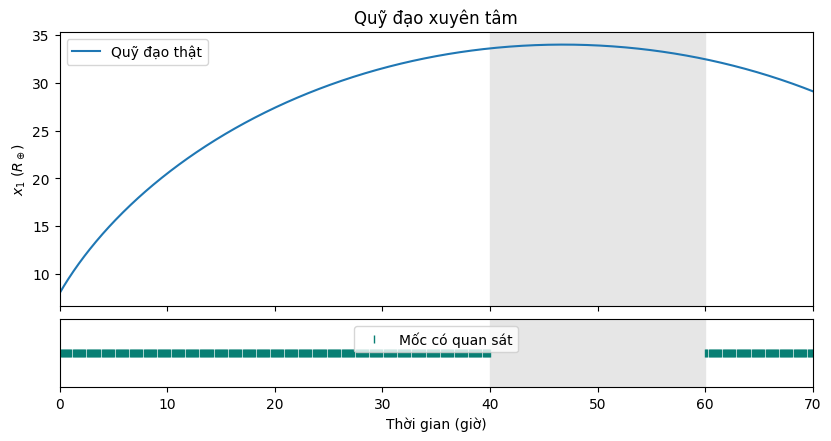

In [4]:
in_gap = (gap_start < time) & (time < gap_end)
has_observation = (time > 0) & ~in_gap
observation_ticks = np.flatnonzero(has_observation)
observations = np.full(time.shape, np.nan)
true_measurement = (true_state @ measurement_matrix.T).ravel()
observations[has_observation] = (
    true_measurement[has_observation]
    + rng.normal(scale=measurement_std, size=observation_ticks.size)
)

fig, (orbit_ax, timeline_ax) = plt.subplots(
    2, 1, figsize=(8.2, 4.3), sharex=True, layout="constrained",
    gridspec_kw={"height_ratios": [4, 1]},
)
orbit_ax.plot(time, true_state[:, 0], label="Quỹ đạo thật")
orbit_ax.set(title="Quỹ đạo xuyên tâm", ylabel=r"$x_1$ ($R_\oplus$)")
orbit_ax.legend()
timeline_ax.plot(
    time[has_observation], np.zeros(observation_ticks.size),
    "|", color="#087F74", label="Mốc có quan sát",
)
timeline_ax.set(xlabel="Thời gian (giờ)", yticks=[])
timeline_ax.legend(loc="upper center")
for ax in (orbit_ax, timeline_ax):
    ax.axvspan(gap_start, gap_end, color="0.9", zorder=0)
    ax.set_xlim(0, duration)
plt.show()
print(f"Số quan sát sử dụng = {observation_ticks.size}")

Với hai bán kính đã chọn, quỹ đạo đạt cực đại ở giờ $46.8$ và
còn $29.115\,R_\oplus$ ở giờ $70$. Các mốc này lệch so với khoảng
$42$ giờ và $26\,R_\oplus$ được mô tả trong sách.

## D. EKF chuẩn liên tục–rời rạc

Tích phân đồng thời $\dot{\hat x}=f(\hat x;\mu_{\rm lọc})$ và
$\dot P=FP+PF^\top+Q$. Tại mốc có dữ liệu, đặt
$S=HP^-H^\top+R$ và $K=P^-H^\top/S$ rồi cập nhật

$$
\hat x^+=\hat x^-+K(y_k-H\hat x^-),\qquad P^+=(I-KH)P^-.
$$

Với $Q=0$, nhiều phép đo có thể làm $P$ và độ lợi $K$ giảm mạnh.
Sai lệch cố định của $\mu$ vẫn tiếp tục tác động lên dự báo.
Trong khoảng mất đo chỉ thực hiện bước dự báo.

In [5]:
def augmented_covariance_dynamics(t, augmented_state, mu):
    estimated_state = augmented_state[:2]
    covariance = augmented_state[2:].reshape(2, 2)
    jacobian = dynamics_jacobian(estimated_state, mu)
    covariance_rate = (
        jacobian @ covariance + covariance @ jacobian.T
        + process_covariance
    )
    return np.r_[
        dynamics(t, estimated_state, mu), covariance_rate.ravel()
    ]


def predict(estimated_state, covariance, elapsed, mu):
    solution = solve_ivp(
        augmented_covariance_dynamics,
        (0, elapsed),
        np.r_[estimated_state, covariance.ravel()],
        args=(mu,),
        method="DOP853",
        first_step=elapsed,
        rtol=1e-10,
        atol=1e-13,
    )
    assert solution.success, solution.message
    return solution.y[:2, -1], solution.y[2:, -1].reshape(2, 2)


def update(estimated_state, covariance, observation):
    cross_covariance = covariance @ measurement_matrix.T
    innovation_variance = (
        (measurement_matrix @ cross_covariance).item()
        + measurement_variance
    )
    kalman_gain = cross_covariance / innovation_variance
    innovation = observation - measurement_matrix @ estimated_state
    estimated_state = estimated_state + kalman_gain @ innovation
    covariance = (
        (identity - kalman_gain @ measurement_matrix) @ covariance
    )
    return estimated_state, covariance

In [6]:
def run_standard_ekf(times, data, mu):
    estimates = np.empty((times.size, 2))
    covariances = np.empty((times.size, 2, 2))
    estimates[0], covariances[0] = initial_estimate, initial_covariance

    for k, elapsed in enumerate(np.diff(times), start=1):
        estimated_state, covariance = predict(
            estimates[k - 1], covariances[k - 1], elapsed, mu
        )
        if np.isfinite(data[k]):
            estimated_state, covariance = update(
                estimated_state, covariance, data[k]
            )
        estimates[k], covariances[k] = estimated_state, covariance

    return estimates, covariances


standard_result = run_standard_ekf(time, observations, mu_filter)

## E. Lọc chỉ dựa trên dữ liệu trong cửa sổ

**Định lý 7.10.** Với hệ tuyến tính, $Q=0$ và cửa sổ đủ quan sát
được, phương trình (7.253) trừ thông tin cũ đã truyền tới mốc hiện
tại khỏi thông tin hậu nghiệm toàn bộ. Ma trận thông tin còn lại
bằng tổng đóng góp của các phép đo được giữ lại theo (7.255).
[Chương 7 §10, tr. 255–258](../../../docs/Stochastic%20Process%20and%20Filter%20Theory/Stochastic%20Processes%20and%20Filtering%20Theory-205-276.pdf#page=62)

**Áp dụng cho quỹ đạo phi tuyến.** Gọi $s$ là trạng thái ở phép đo
đầu tiên trong cửa sổ và $\phi_j(s)$ là trạng thái tích phân từ $s$
đến $t_j$ với $\mu_{\rm lọc}$. Tối thiểu hóa
$\sum_{j\,\mathrm{trong\ cửa\ sổ}}(y_j-H\phi_j(s))^2/R$ bằng
Gauss–Newton. Tích phân $\dot\Phi=F\Phi$ với $\Phi(t_{\rm đầu})=I$,
rồi dùng $A_j=H\Phi_j$ để tuyến tính hóa phần dư. Tại nghiệm,
hiệp phương sai xấp xỉ ở cuối cửa sổ là

$$
P_k=\Phi_k(A^\top R^{-1}A)^{-1}\Phi_k^\top ,
$$

trong đó $R^{-1}$ là trọng số vô hướng chung cho mọi hàng của $A$.
Đây là tổng thông tin kiểu (7.255) áp dụng cho tuyến tính hóa
tại nghiệm, với các hàng quy về đầu cửa sổ rồi truyền $P$ về
cuối cửa sổ. Bài toán tuyến tính cho nghiệm chính xác theo định
lý. Trường hợp này cho nghiệm và hiệp phương sai xấp xỉ cục bộ.

In [7]:
def augmented_transition_dynamics(t, augmented_state, mu):
    state = augmented_state[:2]
    transition = augmented_state[2:].reshape(2, 2)
    transition_rate = dynamics_jacobian(state, mu) @ transition
    return np.r_[dynamics(t, state, mu), transition_rate.ravel()]


def fit_observation_window(times, data, mu):
    offsets = times - times[0]
    # Khởi tạo bằng vị trí đầu và dây cung trong cửa sổ.
    initial_velocity = (data[-1] - data[0]) / offsets[-1]
    start_state = np.array([data[0], initial_velocity])

    for _ in range(8):
        solution = solve_ivp(
            augmented_transition_dynamics,
            (0, offsets[-1]),
            np.r_[start_state, identity.ravel()],
            args=(mu,),
            t_eval=offsets,
            method="DOP853",
            rtol=1e-10,
            atol=1e-13,
        )
        assert solution.success, solution.message
        states = solution.y[:2].T
        transitions = solution.y[2:].T.reshape(-1, 2, 2)
        design = (measurement_matrix @ transitions)[:, 0, :]
        residual = data - (states @ measurement_matrix.T).ravel()
        # R cố định nên triệt tiêu trong bước Gauss–Newton.
        correction, _, rank, _ = np.linalg.lstsq(
            design, residual, rcond=None
        )
        assert rank == 2, "Cửa sổ chưa quan sát được cả hai trạng thái."
        if np.linalg.norm(correction, ord=np.inf) < 1e-11:
            break
        start_state += correction
    else:
        raise RuntimeError("Gauss–Newton chưa hội tụ trong cửa sổ.")

    information = design.T @ design / measurement_variance
    start_covariance = np.linalg.solve(information, identity)
    transition = transitions[-1]
    covariance = transition @ start_covariance @ transition.T
    return states[-1], covariance

Khi chưa đủ $N$ mẫu đầu tiên, dùng tiên nghiệm và các mẫu đã nhận
để khởi động EKF. Khi cửa sổ đầy, bỏ tiên nghiệm và chỉ khớp các
mẫu trong danh sách đang giữ. Cửa sổ cố định xóa một mẫu cũ mỗi
khi thêm một mẫu mới. Cách bỏ theo lô xóa $N$ mẫu cũ khi đủ
$2N$ mẫu, như lịch trong sách với $N=10$. Cả hai cách đều khởi tạo
phép khớp bằng dữ liệu ngay trong cửa sổ. Trong khoảng trống, giữ
nguyên danh sách và truyền trạng thái cùng hiệp phương sai từ
lần cập nhật gần nhất. Cửa sổ đếm theo số quan sát, nên có thể
tạm thời chứa mẫu ở cả hai phía của khoảng trống.

In [8]:
def run_limited_memory(times, data, mu, memory_length, *, batch=False):
    estimates = np.empty((times.size, 2))
    covariances = np.empty((times.size, 2, 2))
    estimates[0], covariances[0] = initial_estimate, initial_covariance
    window_starts = np.full(times.size, -1, dtype=int)
    window_counts = np.zeros(times.size, dtype=int)
    active_ticks = []

    for k, elapsed in enumerate(np.diff(times), start=1):
        observed = np.isfinite(data[k])
        if observed:
            active_ticks.append(k)
            if batch and len(active_ticks) == 2 * memory_length:
                del active_ticks[:memory_length]
            elif not batch and len(active_ticks) > memory_length:
                del active_ticks[0]

        if observed and len(active_ticks) >= memory_length:
            estimates[k], covariances[k] = fit_observation_window(
                times[active_ticks], data[active_ticks], mu
            )
        else:
            estimated_state, covariance = predict(
                estimates[k - 1], covariances[k - 1], elapsed, mu
            )
            if observed:
                estimated_state, covariance = update(
                    estimated_state, covariance, data[k]
                )
            estimates[k], covariances[k] = estimated_state, covariance

        if active_ticks:
            window_starts[k] = active_ticks[0]
        window_counts[k] = len(active_ticks)

    return estimates, covariances, window_starts, window_counts


memory_configurations = {
    "Cửa sổ N=10": (10, False),
    "Cửa sổ N=20": (20, False),
    "Bỏ theo lô 10": (10, True),
}
memory_results = {
    label: run_limited_memory(
        time, observations, mu_filter, length, batch=batch
    )
    for label, (length, batch) in memory_configurations.items()
}
results = {
    "EKF chuẩn": standard_result,
    **{label: result[:2] for label, result in memory_results.items()},
}

## F. Sai số vị trí và vận tốc

Vẽ $e_k=x(t_k)-\hat x_{k|k}$ theo quy ước Hình 8.13–8.14.
Trong dải xám, $\hat x$ là dự báo từ lần quan sát cuối cùng. Trục
sai số vị trí dùng thang log đối xứng với miền tuyến tính
$|e_1|\leq\sigma_y$ để nhìn rõ cả vùng có đo và vùng mất đo.

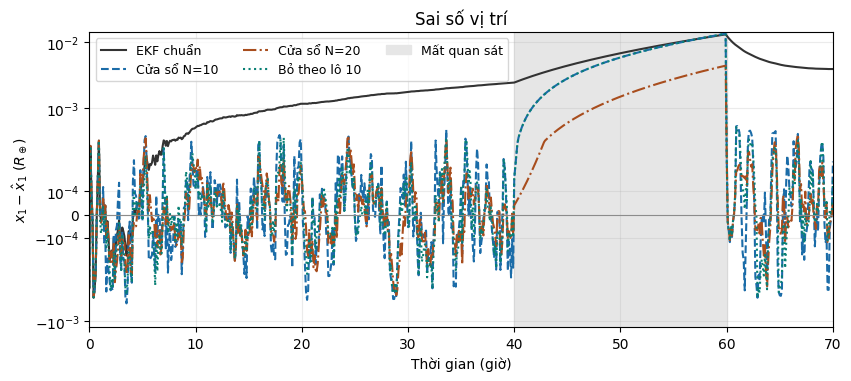

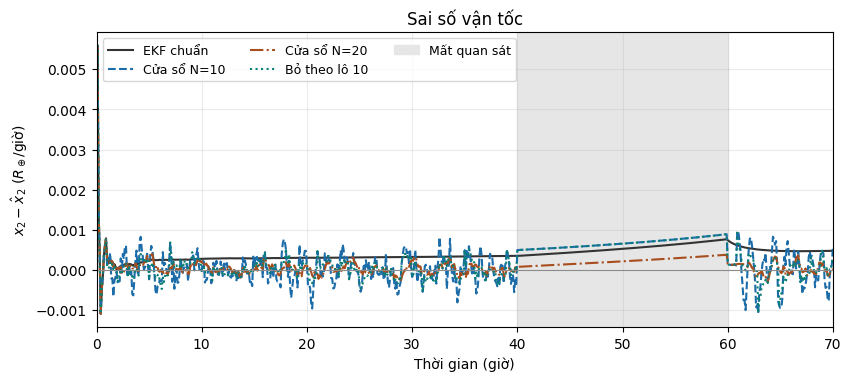

In [9]:
errors = {label: true_state - result[0] for label, result in results.items()}
styles = ("-", "--", "-.", ":")
colors = ("#333333", "#1B6CA8", "#A84D1D", "#087F74")
error_axes = (
    ("Sai số vị trí", r"$x_1-\hat x_1$ ($R_\oplus$)"),
    ("Sai số vận tốc", r"$x_2-\hat x_2$ ($R_\oplus$/giờ)"),
)

for component, (title, ylabel) in enumerate(error_axes):
    _, ax = plt.subplots(figsize=(8.4, 3.7), layout="constrained")
    for (label, error), style, color in zip(errors.items(), styles, colors):
        ax.plot(
            time, error[:, component],
            linestyle=style, color=color, label=label,
        )
    ax.axvspan(gap_start, gap_end, color="0.9", label="Mất quan sát")
    ax.axhline(0, color="0.55", linewidth=0.8)
    if component == 0:
        ax.set_yscale("symlog", linthresh=measurement_std)
    ax.set(title=title, ylabel=ylabel, xlabel="Thời gian (giờ)")
    ax.set_xlim(0, duration)
    ax.grid(alpha=0.25)
    ax.legend(ncol=3, fontsize=9)
    plt.show()

## G. So sánh sai số thực nghiệm với bất định báo cáo

Theo định nghĩa ở tr. 319, tại phép đo thứ $k$ tính

$$
RSS_i(k)=\sqrt{\frac{1}{k}\sum_{j=1}^{k}
  (x_i(t_j)-\hat x_i(t_j\mid t_j))^2},\qquad
RMS_i(k)=\sqrt{P_{ii}(k\mid k)}.
$$

$RSS$ tổng hợp sai số đã xảy ra đến mốc hiện tại, còn $RMS$ lấy từ
hiệp phương sai tại riêng mốc đó. Đồ thị $RSS/RMS$ theo Hình 8.15–8.16
đếm các mốc có phép đo, tiếp tục tổng tích lũy sau khoảng trống và
đánh dấu mức $1$. Đây là chẩn đoán trên một quỹ đạo. Tỷ số còn
phụ thuộc cách $P$ biến thiên theo thời gian.

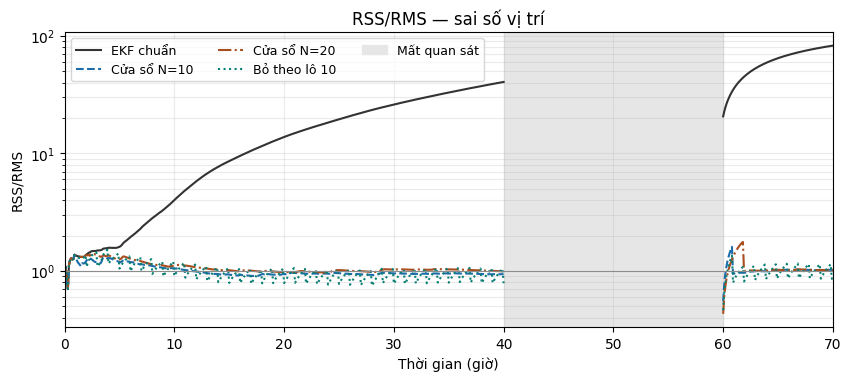

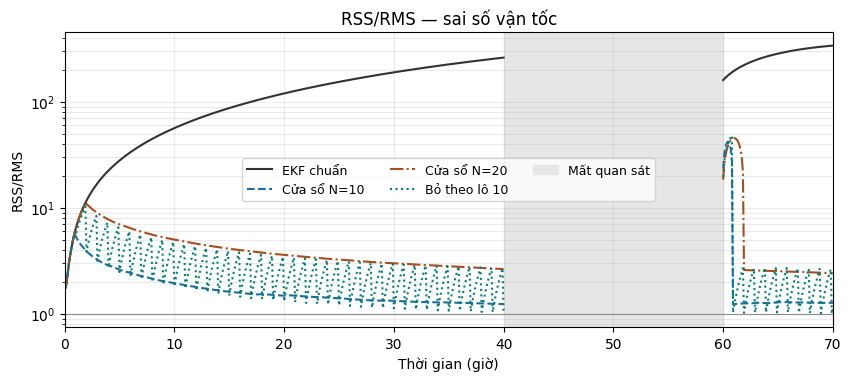

In [10]:
ratios = {}
counts = np.arange(1, observation_ticks.size + 1)[:, None]
for label, (_, covariance) in results.items():
    squared_error = errors[label][observation_ticks]**2
    rss = np.sqrt(np.cumsum(squared_error, axis=0) / counts)
    variances = covariance.diagonal(axis1=1, axis2=2)
    rms = np.sqrt(variances[observation_ticks])
    ratio = np.full_like(true_state, np.nan)
    ratio[observation_ticks] = rss / rms
    ratios[label] = ratio

for component, (name, _) in enumerate(error_axes):
    _, ax = plt.subplots(figsize=(8.4, 3.7), layout="constrained")
    for (label, ratio), style, color in zip(ratios.items(), styles, colors):
        ax.semilogy(
            time, ratio[:, component],
            linestyle=style, color=color, label=label,
        )
    ax.axvspan(gap_start, gap_end, color="0.9", label="Mất quan sát")
    ax.axhline(1, color="0.55", linewidth=0.8)
    ax.set(
        title=f"RSS/RMS — {name.lower()}",
        ylabel="RSS/RMS",
        xlabel="Thời gian (giờ)",
    )
    ax.set_xlim(0, duration)
    ax.grid(alpha=0.25, which="both")
    ax.legend(ncol=3, fontsize=9)
    plt.show()

## H. Độ nhạy với độ dài bộ nhớ và sai lệch mô hình

Tính RMSE riêng trước khoảng trống ($0<t\leq40$ giờ) và sau khi
cả hai cửa sổ cố định đã đủ mẫu mới ($62\leq t\leq70$ giờ).
Chạy thêm đối chứng với $\mu_{\rm thật}$ trên cùng dữ liệu và tiên
nghiệm để tách ảnh hưởng của sai lệch $\mu$ khỏi nhiễu đo. Để thấy
quá trình bắt lại quỹ đạo, so sánh ngay trước và tại phép đo giờ 60.

Mỗi cặp trong bảng đầu ghi vị trí / vận tốc. RMSE có đơn vị $R_\oplus$ và $R_\oplus$/giờ.

In [11]:
control_estimates = {
    "EKF chuẩn": run_standard_ekf(time, observations, mu_true)[0],
    **{
        label: run_limited_memory(
            time, observations, mu_true, length, batch=batch
        )[0]
        for label, (length, batch) in memory_configurations.items()
    },
}

pre_gap = has_observation & (time <= gap_start)
after_recovery = has_observation & (time >= gap_end + 2)
rows = [
    "| Bộ lọc | RMSE trước trống | RMSE sau trống | "
    r"RMSE sau trống, $\mu$ đúng | RSS/RMS ở giờ 70 |",
    "|---|---:|---:|---:|---:|",
]
for label, error in errors.items():
    control_error = true_state - control_estimates[label]
    values = [
        np.sqrt(np.mean(error[pre_gap]**2, axis=0)),
        np.sqrt(np.mean(error[after_recovery]**2, axis=0)),
        np.sqrt(np.mean(control_error[after_recovery]**2, axis=0)),
    ]
    cells = [" / ".join(f"{value:.2e}" for value in pair) for pair in values]
    ratio_at_end = " / ".join(f"{value:.2f}" for value in ratios[label][-1])
    rows.append("| " + " | ".join([label, *cells, ratio_at_end]) + " |")

display(Markdown("\n".join(rows)))

resume_tick = np.searchsorted(time, gap_end)
rows = [
    r"| Bộ lọc | $\lvert e_1\rvert$ tại 59.9 h ($R_\oplus$) | "
    r"$\lvert e_1\rvert$ tại 60 h ($R_\oplus$) | RSS/RMS vận tốc tại 60 h |",
    "|---|---:|---:|---:|",
]
for label, error in errors.items():
    before, after = np.abs(error[[resume_tick - 1, resume_tick], 0])
    velocity_ratio = ratios[label][resume_tick, 1]
    rows.append(
        f"| {label} | {before:.2e} | {after:.2e} | {velocity_ratio:.2f} |"
    )
display(Markdown("\n".join(rows)))

| Bộ lọc | RMSE trước trống | RMSE sau trống | RMSE sau trống, $\mu$ đúng | RSS/RMS ở giờ 70 |
|---|---:|---:|---:|---:|
| EKF chuẩn | 1.36e-03 / 4.19e-04 | 4.69e-03 / 4.83e-04 | 6.10e-05 / 2.45e-06 | 82.57 / 337.52 |
| Cửa sổ N=10 | 1.74e-04 / 4.32e-04 | 2.36e-04 / 4.76e-04 | 2.36e-04 / 4.76e-04 | 1.02 / 1.27 |
| Cửa sổ N=20 | 1.35e-04 / 3.25e-04 | 1.48e-04 / 1.42e-04 | 1.47e-04 / 1.42e-04 | 1.01 / 2.42 |
| Bỏ theo lô 10 | 1.46e-04 / 3.58e-04 | 1.95e-04 / 3.07e-04 | 1.95e-04 / 3.09e-04 | 0.89 / 1.16 |

| Bộ lọc | $\lvert e_1\rvert$ tại 59.9 h ($R_\oplus$) | $\lvert e_1\rvert$ tại 60 h ($R_\oplus$) | RSS/RMS vận tốc tại 60 h |
|---|---:|---:|---:|
| EKF chuẩn | 1.31e-02 | 1.25e-02 | 159.92 |
| Cửa sổ N=10 | 1.35e-02 | 2.57e-04 | 23.46 |
| Cửa sổ N=20 | 4.41e-03 | 2.74e-04 | 18.40 |
| Bỏ theo lô 10 | 1.35e-02 | 2.56e-04 | 19.56 |

## I. Kiểm tra số và kết luận

Kiểm tra trạng thái hữu hạn, tính đối xứng và nửa xác định dương
của $P$, lịch đo, và số mẫu được giữ theo từng chính sách. Kiểm tra
tính độc lập của cửa sổ bằng cách sửa mọi quan sát đã bị loại
trước một mốc sau khoảng trống rồi chạy lại bộ lọc đến mốc đó.

In [12]:
assert np.isnan(observations[in_gap]).all()
assert np.array_equal(np.isfinite(observations), has_observation)
assert not has_observation[0] and has_observation[resume_tick]
assert has_observation[np.searchsorted(time, gap_start)]
assert np.count_nonzero(in_gap) == 199 and observation_ticks.size == 501

observation_count = np.cumsum(has_observation)
verified_index = np.searchsorted(time, gap_end + 2)
for label, (length, batch) in memory_configurations.items():
    estimates, covariances, starts, sizes = memory_results[label]
    expected_sizes = np.minimum(observation_count, length)
    if batch:
        full = observation_count >= length
        expected_sizes[full] = length + observation_count[full] % length
    np.testing.assert_array_equal(sizes, expected_sizes)
    nonempty = sizes > 0
    expected_starts = observation_ticks[
        observation_count[nonempty] - sizes[nonempty]
    ]
    np.testing.assert_array_equal(starts[nonempty], expected_starts)

    # Sửa dữ liệu đã loại, giữ nguyên khoảng trống và cửa sổ đang dùng.
    altered_data = observations[:verified_index + 1].copy()
    discarded = observation_ticks[observation_ticks < starts[verified_index]]
    assert discarded.size > 0
    altered_data[discarded] += 5 * measurement_std
    altered = run_limited_memory(
        time[:verified_index + 1], altered_data, mu_filter, length,
        batch=batch,
    )
    np.testing.assert_allclose(
        altered[0][-1], estimates[verified_index], rtol=0, atol=1e-11
    )
    np.testing.assert_allclose(
        altered[1][-1], covariances[verified_index], rtol=0, atol=1e-13
    )

last_before_gap = np.searchsorted(time, gap_start)
for estimates, covariances in results.values():
    assert np.isfinite(estimates).all() and np.isfinite(covariances).all()
    np.testing.assert_allclose(
        covariances, covariances.swapaxes(1, 2), rtol=0, atol=1e-12
    )
    assert np.min(np.linalg.eigvalsh(covariances)) >= -1e-12
    predicted_at_gap_end = predict(
        estimates[last_before_gap],
        covariances[last_before_gap],
        time[resume_tick - 1] - time[last_before_gap],
        mu_filter,
    )
    np.testing.assert_allclose(
        predicted_at_gap_end[0], estimates[resume_tick - 1],
        rtol=0, atol=1e-8,
    )
    np.testing.assert_allclose(
        predicted_at_gap_end[1], covariances[resume_tick - 1],
        rtol=0, atol=1e-11,
    )

print("Đạt kiểm tra lịch đo, trạng thái hữu hạn, P và chiều dài cửa sổ.")
print("Thay dữ liệu cũ không làm đổi nghiệm và P tại mốc kiểm tra.")

Đạt kiểm tra lịch đo, trạng thái hữu hạn, P và chiều dài cửa sổ.
Thay dữ liệu cũ không làm đổi nghiệm và P tại mốc kiểm tra.


Khi đặt $\mu=0$, vận tốc không đổi và mô hình trở thành tuyến tính.
Kiểm tra rằng nghiệm bình phương tối thiểu trên cửa sổ đầu tiên
khớp với phép trừ thông tin (7.253), kể cả khi bỏ tiên nghiệm.

In [13]:
linear_times = time[:11]
linear_data = observations[:11]
linear_states, linear_covariances = run_standard_ekf(
    linear_times, linear_data, 0.0
)
prior_state, prior_covariance = predict(
    initial_estimate, initial_covariance, linear_times[-1], 0.0
)
posterior_information = np.linalg.solve(linear_covariances[-1], identity)
prior_information = np.linalg.solve(prior_covariance, identity)
theorem_covariance = np.linalg.solve(
    posterior_information - prior_information, identity
)
theorem_estimate = theorem_covariance @ (
    posterior_information @ linear_states[-1]
    - prior_information @ prior_state
)
window_estimate, window_covariance = fit_observation_window(
    linear_times[1:], linear_data[1:], 0.0
)
np.testing.assert_allclose(window_estimate, theorem_estimate, atol=1e-11)
np.testing.assert_allclose(window_covariance, theorem_covariance, atol=1e-13)
print("Cửa sổ khớp phép trừ thông tin (7.253) trong trường hợp tuyến tính.")

Cửa sổ khớp phép trừ thông tin (7.253) trong trường hợp tuyến tính.


### Kết luận

- **Sai lệch mô hình.** EKF chuẩn với $\mu$ bị lệch cho RSS/RMS ở giờ
  70 khoảng $83$ cho vị trí và $338$ cho vận tốc. Với $\mu$ đúng,
  RMSE vị trí sau khi có lại dữ liệu giảm từ $4.69\times10^{-3}$ xuống
  $6.10\times10^{-5}\,R_\oplus$. Sai lệch quỹ đạo tích lũy trong khi
  $P$ và độ lợi giảm, nên bộ lọc đánh giá quá thấp sai số của chính nó.
- **Bỏ thông tin cũ.** Khớp lại trên mẫu còn giữ làm giảm ảnh hưởng
  của mô hình sai ở các đoạn xa. Lịch bỏ theo lô tạo dao động của
  RSS/RMS tương tự Hình 8.15–8.16. Các cửa sổ cố định cho thấy mức
  bất định và sai số phụ thuộc vào cả chính sách bỏ mẫu.
- **Mất và có lại quan sát.** Trong khoảng trống, mô hình sai tiếp
  tục chi phối dự báo. Ở giờ 60, các cửa sổ kéo sai số vị trí về
  cỡ $3\times10^{-4}\,R_\oplus$. Tỷ số vận tốc vẫn tăng đột biến
  lúc đó vì $RSS$ còn chứa lịch sử, còn mẫu mới làm thay đổi $RMS$
  ngay lập tức. Các mẫu trước khoảng trống rời dần khỏi cửa sổ.
- **Độ dài bộ nhớ.** Sau gián đoạn, $N=20$ cho RMSE vị trí và vận tốc
  thấp hơn $N=10$ trong lần chạy này. Cửa sổ dài làm giảm ảnh hưởng
  của nhiễu đo nhưng buộc mô hình khớp lâu hơn, nên có thể làm tăng
  độ chệch khi động lực sai. RMSE thấp hơn vẫn có thể đi cùng tỷ số
  RSS/RMS cao hơn nếu $P$ giảm nhanh hơn sai số.
- **Phạm vi đối chiếu.** Tham số động lực, nhiễu đo, lịch và chẩn
  đoán lấy từ §12. Các đường cong phụ thuộc vào cách dựng trạng
  thái đầu, tiên nghiệm, mẫu nhiễu và xấp xỉ Gauss–Newton. Xu hướng
  mất nhất quán của EKF và phục hồi của cửa sổ được tái hiện định tính.